In [1]:
# %%
import pandas as pd
from pathlib import Path

# Raiz do projeto: a pasta que contém UCMF_raw.csv. Procurar a partir da pasta atual
# para cima faz o notebook funcionar rodando da própria subpasta ou da raiz.
RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "UCMF_raw.csv").exists())
PASTA = RAIZ / "Análise Univariada"   # tabelas e figuras desta análise
DOCS = RAIZ / "Docs"                  # documentação (regra de conversão)

df = pd.read_csv(RAIZ / "UCMF_raw.csv", dtype=str, keep_default_na=False)

print(df.shape)
print(df.columns.tolist())

(12873, 21)
['ID', 'Peso', 'Altura', 'IMC', 'Atendimento', 'DN', 'IDADE', 'Convenio', 'PULSOS', 'PA SISTOLICA', 'PA DIASTOLICA', 'PPA', 'NORMAL X ANORMAL', 'B2', 'SOPRO', 'FC', 'HDA 1', 'HDA2', 'SEXO', 'MOTIVO1', 'MOTIVO2']


In [2]:
# %%
def converte_data(coluna):
    texto = pd.to_datetime(coluna, format="%d/%m/%y", errors="coerce")              #tenta ler a string no formato dia/mês/ano-2-dígitos. errors="coerce" faz o que não bate virar NaT (o "vazio" do tipo data) em vez de travar o script
    serial = pd.to_numeric(coluna, errors="coerce")                         #tenta ler como número puro; texto vira NaN
    excel = pd.to_datetime(serial, unit="D", origin="1899-12-30", errors="coerce")      #interpreta esse número como "dias desde 30/12/1899" — é a contagem interna que o Excel usa para guardar datas.
    return texto.fillna(excel)

df["Atendimento_dt"] = converte_data(df["Atendimento"])
df["DN_dt"] = converte_data(df["DN"])

for original, nova in [("Atendimento", "Atendimento_dt"), ("DN", "DN_dt")]:
    vazio = (df[original].str.strip() == "").sum()
    invalido = ((df[original].str.strip() != "") & df[nova].isna()).sum()
    valido = df[nova].notna().sum()
    print(f"{original}: válido={valido} vazio={vazio} formato_inválido={invalido}")
    print(f"  min={df[nova].min()}  max={df[nova].max()}")

Atendimento: válido=11890 vazio=983 formato_inválido=0
  min=1967-12-31 00:00:00  max=2066-08-22 00:00:00
DN: válido=11377 vazio=1376 formato_inválido=120
  min=1969-07-14 00:00:00  max=2068-07-06 00:00:00


In [3]:
# %%
df["FC_num"] = pd.to_numeric(df["FC"], errors="coerce")

vazio = (df["FC"].str.strip() == "").sum()
invalido_mask = df["FC"].str.strip().ne("") & df["FC_num"].isna()
invalido = invalido_mask.sum()
valido = df["FC_num"].notna().sum()

print(f"FC: válido={valido} vazio={vazio} texto_não_numérico={invalido}")
print("exemplos de texto não numérico:", sorted(df["FC"][invalido_mask].unique())[:5])
print(df["FC_num"].describe())

FC: válido=10989 vazio=1868 texto_não_numérico=16
exemplos de texto não numérico: ['120-160', '120-180', '140-120', '140-150', '140-160']
count    10989.000000
mean        96.635909
std         92.705713
min          8.000000
25%         80.000000
50%         92.000000
75%        100.000000
max       9288.000000
Name: FC_num, dtype: float64


In [4]:
# %%
for col in ["Peso", "Altura", "IMC", "IDADE"]:
    df[col + "_num"] = pd.to_numeric(df[col], errors="coerce")

print("Peso   -> zeros:", (df["Peso_num"]==0).sum(), " | negativos:", (df["Peso_num"]<0).sum())
print("Altura -> zeros:", (df["Altura_num"]==0).sum(), " | valor 99:", (df["Altura_num"]==99).sum())
print("IMC    -> zeros:", (df["IMC_num"]==0).sum())
print("IDADE  -> zeros:", (df["IDADE_num"]==0).sum(), " | negativos:", (df["IDADE_num"]<0).sum(), " | mínimo:", df["IDADE_num"].min())

# aplica a regra mínima: só o que é fisicamente impossível vira ausente
df["Peso_limpo"]   = df["Peso_num"].mask(df["Peso_num"] == 0)
df["Altura_limpo"] = df["Altura_num"].mask(df["Altura_num"] == 0)   # 99 fica — ver explicação
df["IMC_limpo"]    = df["IMC_num"].mask(df["IMC_num"] == 0)
df["IDADE_limpo"]  = df["IDADE_num"]                                 # nada convertido aqui

print("\nn válido após a conversão:")
for col in ["Peso_limpo", "Altura_limpo", "IMC_limpo", "IDADE_limpo"]:
    print(f"  {col}: {df[col].notna().sum()}")

Peso   -> zeros: 2609  | negativos: 1
Altura -> zeros: 4460  | valor 99: 81
IMC    -> zeros: 109


IDADE  -> zeros: 184  | negativos: 122  | mínimo: -113.18

n válido após a conversão:
  Peso_limpo: 9946
  Altura_limpo: 8413
  IMC_limpo: 8037
  IDADE_limpo: 11377


In [5]:
# %%
print(df["PPA"].value_counts(dropna=False))

codigos_faltantes_ppa = ["", "Não Calculado", "#VALUE!"]
df["PPA_limpo"] = df["PPA"].replace(codigos_faltantes_ppa, pd.NA)

print("\nn válido PPA:", df["PPA_limpo"].notna().sum())
print("n ausente (vazio + código):", df["PPA_limpo"].isna().sum())

PPA
Não Calculado          9081
Normal                 1790
#VALUE!                1496
                        217
HAS-2 PAS                73
Pre-Hipertensão PAD      73
Pre-Hipertensão PAS      48
HAS-1 PAS                48
HAS-1 PAD                26
HAS-2 PAD                21
Name: count, dtype: int64

n válido PPA: 2079
n ausente (vazio + código): 10794


In [6]:
# %%
cols_categoricas = ["PULSOS","B2","SOPRO","NORMAL X ANORMAL","SEXO","HDA 1","HDA2","MOTIVO1","MOTIVO2"]
for col in cols_categoricas:
    df[col] = df[col].str.strip()

# mapeamentos explícitos: só grafia, nunca junta conceito clínico diferente
mapa_pulsos = {"NORMAIS": "Normais", "AMPLOS": "Amplos"}
mapa_sopro  = {"sistólico": "Sistólico", "contínuo": "Contínuo"}
mapa_alvo   = {"anormal": "Anormal", "Normais": "Normal"}
mapa_sexo   = {"M": "Masculino", "masculino": "Masculino", "F": "Feminino"}

df["PULSOS_pad"] = df["PULSOS"].replace(mapa_pulsos)
df["SOPRO_pad"]  = df["SOPRO"].replace(mapa_sopro)
df["ALVO_pad"]   = df["NORMAL X ANORMAL"].replace(mapa_alvo)
df["SEXO_pad"]   = df["SEXO"].replace(mapa_sexo)

for original, pad in [("PULSOS","PULSOS_pad"), ("SOPRO","SOPRO_pad"),
                       ("NORMAL X ANORMAL","ALVO_pad"), ("SEXO","SEXO_pad")]:
    brutas = df[original][df[original]!=""].nunique()
    padronizadas = df[pad][df[pad]!=""].nunique()
    print(f"{original}: {brutas} brutas -> {padronizadas} padronizadas")

df["SEXO_pad"] = df["SEXO_pad"].replace("Indeterminado", "")

PULSOS: 7 brutas -> 5 padronizadas
SOPRO: 7 brutas -> 5 padronizadas
NORMAL X ANORMAL: 4 brutas -> 2 padronizadas
SEXO: 6 brutas -> 3 padronizadas


In [7]:
# %%
regra_conversao = pd.DataFrame([
    ["Atendimento", "dd/mm/aa",                     "formato recuperável",   "→ data",                        11578],
    ["Atendimento", "número de 5 dígitos",           "serial do Excel",       "→ data (origem 30/12/1899)",     312],
    ["DN",          "dd/mm/aa",                      "formato recuperável",   "→ data",                        11253],
    ["DN",          "número de 5 dígitos",           "serial do Excel",       "→ data (origem 30/12/1899)",     124],
    ["DN",          'ex.: "4/anos", "18/10,1996"',   "formato inválido",      "→ ausente",                       120],
    ["FC",          'ex.: "80-90", "120-160"',       "não numérico",          "→ ausente",                        16],
    ["Peso",        "0",                             "código de faltante",    "→ ausente",                      2609],
    ["Altura",      "0",                             "código de faltante",    "→ ausente",                      4460],
    ["IMC",         "0",                             "código de faltante",    "→ ausente",                       109],
    ["PPA",         "Não Calculado",                 "código de faltante",    "→ ausente",                      9081],
    ["PPA",         "#VALUE!",                       "código de faltante",    "→ ausente",                      1496],
    ["PULSOS",      "NORMAIS, AMPLOS",               "grafia inconsistente",  "→ forma padrão",                    3],
    ["SOPRO",       "sistólico, contínuo",           "grafia inconsistente",  "→ forma padrão",                  751],
    ["NORMAL X ANORMAL (alvo)", "anormal, Normais",  "grafia inconsistente",  "→ forma padrão",                    2],
    ["SEXO",        "M, F, masculino",               "grafia inconsistente",  "→ forma padrão",                10621],
    ["SEXO", "Indeterminado", "código de faltante", "→ ausente", 1417],
], columns=["Variável","Valor encontrado","Tipo","Ação","n afetados"])

print(regra_conversao.to_string(index=False))
regra_conversao.to_csv(DOCS / "regra_conversao.csv", index=False)

               Variável            Valor encontrado                 Tipo                       Ação  n afetados
            Atendimento                    dd/mm/aa  formato recuperável                     → data       11578
            Atendimento         número de 5 dígitos      serial do Excel → data (origem 30/12/1899)         312
                     DN                    dd/mm/aa  formato recuperável                     → data       11253
                     DN         número de 5 dígitos      serial do Excel → data (origem 30/12/1899)         124
                     DN ex.: "4/anos", "18/10,1996"     formato inválido                  → ausente         120
                     FC     ex.: "80-90", "120-160"         não numérico                  → ausente          16
                   Peso                           0   código de faltante                  → ausente        2609
                 Altura                           0   código de faltante                  → ausente     

In [8]:
# %%
df["PAS_num"] = pd.to_numeric(df["PA SISTOLICA"], errors="coerce")
df["PAD_num"] = pd.to_numeric(df["PA DIASTOLICA"], errors="coerce")

variaveis_A = {
    "Peso": "Peso_limpo", "Altura": "Altura_limpo", "IMC": "IMC_limpo",
    "IDADE": "IDADE_limpo", "PAS": "PAS_num", "PAD": "PAD_num", "FC": "FC_num",
}

n_total = len(df)
linhas = []
for nome, col in variaveis_A.items():
    s = df[col]
    desc = s.describe()
    linhas.append({
        "Variável": nome,
        "n válido": int(desc["count"]),
        "% ausente": round((n_total - desc["count"]) / n_total * 100, 1),
        "mín": round(desc["min"], 2), "Q1": round(desc["25%"], 2),
        "mediana": round(desc["50%"], 2), "média": round(desc["mean"], 2),
        "Q3": round(desc["75%"], 2), "máx": round(desc["max"], 2),
        "DP": round(desc["std"], 2), "IQR": round(desc["75%"] - desc["25%"], 2),
        "assimetria": round(s.skew(), 2),
    })

tabela_A = pd.DataFrame(linhas)
print(tabela_A.to_string(index=False))
tabela_A.to_csv(PASTA / "tabela_A.csv", index=False)

Variável  n válido  % ausente     mín    Q1  mediana  média     Q3     máx    DP   IQR  assimetria
    Peso      9946       22.7  -40.00  9.02    16.00  20.97  28.00  157.00 16.51 18.98        1.46
  Altura      8413       34.6   10.00 71.00   100.00 101.16 129.00  198.00 35.46 58.00        0.17
     IMC      8037       37.6    2.00 15.00    17.00  17.69  19.00  848.00 14.97  4.00       44.09
   IDADE     11377       11.6 -113.18  0.93     3.96   4.86   8.59   71.81  8.83  7.66       -7.83
     PAS      5143       60.0   60.00 90.00   100.00 101.80 110.00  990.00 18.90 20.00       26.61
     PAD      5133       60.1    6.00 60.00    60.00  62.65  70.00  120.00  9.09 10.00        0.92
      FC     10989       14.6    8.00 80.00    92.00  96.64 100.00 9288.00 92.71 20.00       89.49


In [9]:
# %%
variaveis_B = {
    "PULSOS": ("PULSOS", "PULSOS_pad"),
    "B2": ("B2", "B2"),
    "SOPRO": ("SOPRO", "SOPRO_pad"),
    "PPA": ("PPA", "PPA_limpo"),
    "NORMAL X ANORMAL (alvo)": ("NORMAL X ANORMAL", "ALVO_pad"),
    "SEXO": ("SEXO", "SEXO_pad"),
    "HDA 1": ("HDA 1", "HDA 1"),
    "HDA2": ("HDA2", "HDA2"),
    "MOTIVO1": ("MOTIVO1", "MOTIVO1"),
    "MOTIVO2": ("MOTIVO2", "MOTIVO2"),
}

linhas = []
for nome, (bruta, pad) in variaveis_B.items():
    s = df[pad].replace("", pd.NA)
    validos = s.dropna()
    contagem = validos.value_counts()
    n_moda = contagem.max()
    modas = contagem[contagem == n_moda].index.tolist()
    linhas.append({
        "Variável": nome,
        "n válido": len(validos),
        "% ausente": round(s.isna().mean() * 100, 1),
        "categ. brutas": df[bruta][df[bruta].str.strip() != ""].nunique(),
        "categ. padronizadas": validos.nunique(),
        "moda": " / ".join(modas),
        "% moda (÷ n total)": round(n_moda / n_total * 100, 1),
        "% moda (÷ n válido)": round(n_moda / len(validos) * 100, 1),
    })

tabela_B = pd.DataFrame(linhas)
print(tabela_B.to_string(index=False))
tabela_B.to_csv(PASTA / "tabela_B.csv", index=False)

               Variável  n válido  % ausente  categ. brutas  categ. padronizadas                     moda  % moda (÷ n total)  % moda (÷ n válido)
                 PULSOS     11679        9.3              7                    5                  Normais                89.6                 98.7
                     B2     11695        9.2              5                    5                   Normal                86.2                 94.9
                  SOPRO     11706        9.1              7                    5                  ausente                56.5                 62.1
                    PPA      2079       83.8              9                    7                   Normal                13.9                 86.1
NORMAL X ANORMAL (alvo)     11705        9.1              4                    2                   Normal                52.4                 57.6
                   SEXO     11452       11.0              6                    2                Masculino             

In [10]:
# %%
hoje = pd.Timestamp("2026-09-25")

# ID
print(f"ID: {df['ID'].nunique()} distintos em {n_total} registros")

# Convenio
conv = df["Convenio"][df["Convenio"].str.strip() != ""]
print(f"Convenio: n válido {len(conv)}; % ausente {round((n_total - len(conv)) / n_total * 100, 1)}; "
      f"{conv.nunique()} grafias distintas ({conv.str.strip().str.upper().nunique()} se ignorar maiúsc./minúsc.)")

# DN
dn_vazio = (df["DN"].str.strip() == "").sum()
dn_invalido = ((df["DN"].str.strip() != "") & df["DN_dt"].isna()).sum()
print(f"DN: n válido {df['DN_dt'].notna().sum()} (vazios {dn_vazio}; formato inválido {dn_invalido}); "
      f"de {df['DN_dt'].min().date()} a {df['DN_dt'].max().date()}; datas no futuro: {(df['DN_dt'] > hoje).sum()}")

# Atendimento
print(f"Atendimento: n válido {df['Atendimento_dt'].notna().sum()}; "
      f"de {df['Atendimento_dt'].min().date()} a {df['Atendimento_dt'].max().date()}; "
      f"datas no futuro: {(df['Atendimento_dt'] > hoje).sum()}")

ID: 12873 distintos em 12873 registros
Convenio: n válido 8765; % ausente 31.9; 374 grafias distintas (275 se ignorar maiúsc./minúsc.)
DN: n válido 11377 (vazios 1376; formato inválido 120); de 1969-07-14 a 2068-07-06; datas no futuro: 11
Atendimento: n válido 11890; de 1967-12-31 a 2066-08-22; datas no futuro: 1


In [11]:
# %%
# Variáveis que não entram nas tabelas A e B (identificador, administrativa e datas): uma
# linha para cada, com n válido, % ausente e o problema principal, para que a análise
# univariada cubra todas as variáveis da base.
serial_dn = df["DN"].str.strip().str.fullmatch(r"[0-9]{5}")
serial_atend = df["Atendimento"].str.strip().str.fullmatch(r"[0-9]{5}")


def pct_ausente(n_validos):
    return round((n_total - n_validos) / n_total * 100, 1)


n_id = int((df["ID"].str.strip() != "").sum())
n_dn = int(df["DN_dt"].notna().sum())
n_atend = int(df["Atendimento_dt"].notna().sum())

tabela_C = pd.DataFrame([
    {"Variável": "ID", "n válido": n_id, "% ausente": pct_ausente(n_id),
     "problema principal": f"identificador: {df['ID'].nunique()} valores distintos em {n_total} "
                           "registros; sem informação clínica"},
    {"Variável": "Convenio", "n válido": len(conv), "% ausente": pct_ausente(len(conv)),
     "problema principal": f"{conv.nunique()} grafias distintas ({conv.str.strip().str.upper().nunique()} "
                           "ignorando maiúsc./minúsc.) para os mesmos planos; sem relação clínica com o alvo"},
    {"Variável": "DN", "n válido": n_dn, "% ausente": pct_ausente(n_dn),
     "problema principal": f"{dn_invalido} valores em formato inválido (ex.: '4/anos'), "
                           f"{int(serial_dn.sum())} datas gravadas como serial do Excel e "
                           f"{int((df['DN_dt'] > hoje).sum())} datas no futuro (ano de 2 dígitos lido "
                           "no século errado)"},
    {"Variável": "Atendimento", "n válido": n_atend, "% ausente": pct_ausente(n_atend),
     "problema principal": f"{int(serial_atend.sum())} datas gravadas como serial do Excel e "
                           f"{int((df['Atendimento_dt'] > hoje).sum())} data(s) no futuro"},
])
print(tabela_C.to_string(index=False))
tabela_C.to_csv(PASTA / "tabela_C.csv", index=False)

   Variável  n válido  % ausente                                                                                                                                     problema principal
         ID     12873        0.0                                                                      identificador: 12873 valores distintos em 12873 registros; sem informação clínica
   Convenio      8765       31.9                                            374 grafias distintas (275 ignorando maiúsc./minúsc.) para os mesmos planos; sem relação clínica com o alvo
         DN     11377       11.6 120 valores em formato inválido (ex.: '4/anos'), 124 datas gravadas como serial do Excel e 11 datas no futuro (ano de 2 dígitos lido no século errado)
Atendimento     11890        7.6                                                                                          312 datas gravadas como serial do Excel e 1 data(s) no futuro


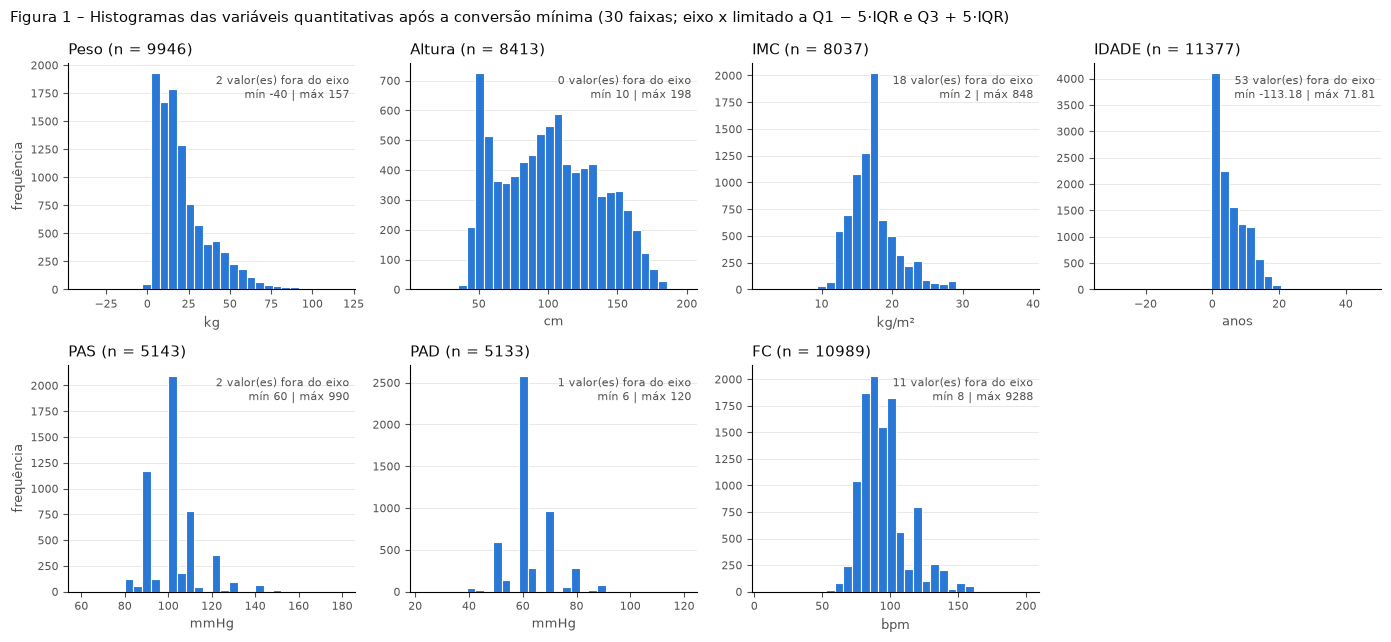

In [12]:
# %%
import matplotlib.pyplot as plt

AZUL, TEXTO, TEXTO2, GRADE = "#2a78d6", "#0b0b0b", "#52514e", "#e5e5e2"
N_FAIXAS = 30
unidades = {"Peso": "kg", "Altura": "cm", "IMC": "kg/m²", "IDADE": "anos",
            "PAS": "mmHg", "PAD": "mmHg", "FC": "bpm"}

fig, eixos = plt.subplots(2, 4, figsize=(14, 6.5))
eixos = eixos.flatten()

for ax, (nome, col) in zip(eixos, variaveis_A.items()):
    s = df[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lim_inf = max(s.min(), q1 - 5 * iqr)
    lim_sup = min(s.max(), q3 + 5 * iqr)
    dentro = s[(s >= lim_inf) & (s <= lim_sup)]
    fora = len(s) - len(dentro)

    ax.hist(dentro, bins=N_FAIXAS, color=AZUL, edgecolor="white", linewidth=0.8)
    ax.set_title(f"{nome} (n = {len(s)})", loc="left", fontsize=11, color=TEXTO)
    ax.set_xlabel(unidades[nome], fontsize=9, color=TEXTO2)
    ax.text(0.98, 0.95, f"{fora} valor(es) fora do eixo\nmín {s.min():g} | máx {s.max():g}",
            transform=ax.transAxes, ha="right", va="top", fontsize=8, color=TEXTO2)
    ax.grid(axis="y", color=GRADE, linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(colors=TEXTO2, labelsize=8)

eixos[-1].axis("off")
eixos[0].set_ylabel("frequência", fontsize=9, color=TEXTO2)
eixos[4].set_ylabel("frequência", fontsize=9, color=TEXTO2)
fig.suptitle("Figura 1 – Histogramas das variáveis quantitativas após a conversão mínima "
             "(30 faixas; eixo x limitado a Q1 − 5·IQR e Q3 + 5·IQR)",
             x=0.01, ha="left", fontsize=11, color=TEXTO)
fig.tight_layout()
fig.savefig(PASTA / "fig1_histogramas.png", dpi=200, bbox_inches="tight")
plt.show()

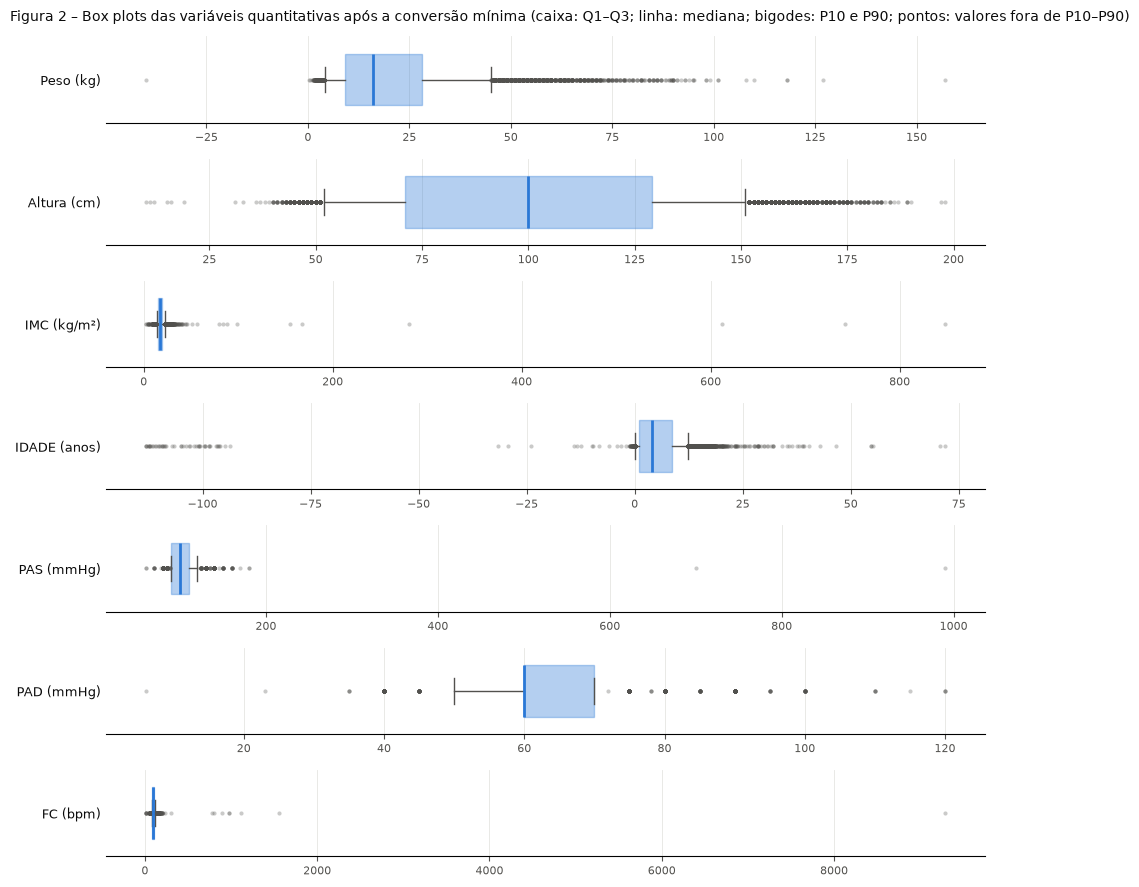

In [13]:
# %%
fig, eixos = plt.subplots(7, 1, figsize=(10, 9))

for ax, (nome, col) in zip(eixos, variaveis_A.items()):
    s = df[col].dropna()
    ax.boxplot(s, orientation="horizontal", whis=(10, 90), widths=0.6, patch_artist=True,
               boxprops=dict(facecolor=AZUL, edgecolor=AZUL, alpha=0.35),
               medianprops=dict(color=AZUL, linewidth=2),
               whiskerprops=dict(color=TEXTO2), capprops=dict(color=TEXTO2),
               flierprops=dict(marker="o", markersize=3, markerfacecolor=TEXTO2,
                               markeredgecolor="none", alpha=0.3))
    ax.set_yticks([1])
    ax.set_yticklabels([f"{nome} ({unidades[nome]})"], fontsize=9, color=TEXTO)
    ax.grid(axis="x", color=GRADE, linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="x", colors=TEXTO2, labelsize=8)
    ax.tick_params(axis="y", length=0)

fig.suptitle("Figura 2 – Box plots das variáveis quantitativas após a conversão mínima "
             "(caixa: Q1–Q3; linha: mediana; bigodes: P10 e P90; pontos: valores fora de P10–P90)",
             x=0.01, ha="left", fontsize=10, color=TEXTO)
fig.tight_layout()
fig.savefig(PASTA / "fig2_boxplots.png", dpi=200, bbox_inches="tight")
plt.show()

                  vazio  código/inválido  total
Variável                                       
Atendimento         7.6              0.0    7.6
MOTIVO1             8.2              0.0    8.2
SOPRO               9.1              0.0    9.1
NORMAL X ANORMAL    9.1              0.0    9.1
B2                  9.2              0.0    9.2
PULSOS              9.3              0.0    9.3
SEXO                0.0             11.0   11.0
DN                 10.7              0.9   11.6
IDADE              11.6              0.0   11.6
FC                 14.5              0.1   14.6
Peso                2.5             20.3   22.7
MOTIVO2            27.2              0.0   27.2
Convenio           31.9              0.0   31.9
HDA 1              33.2              0.0   33.2
Altura              0.0             34.6   34.6
IMC                36.7              0.8   37.6
PAS                60.0              0.0   60.0
PAD                60.1              0.0   60.1
PPA                 1.7             82.2

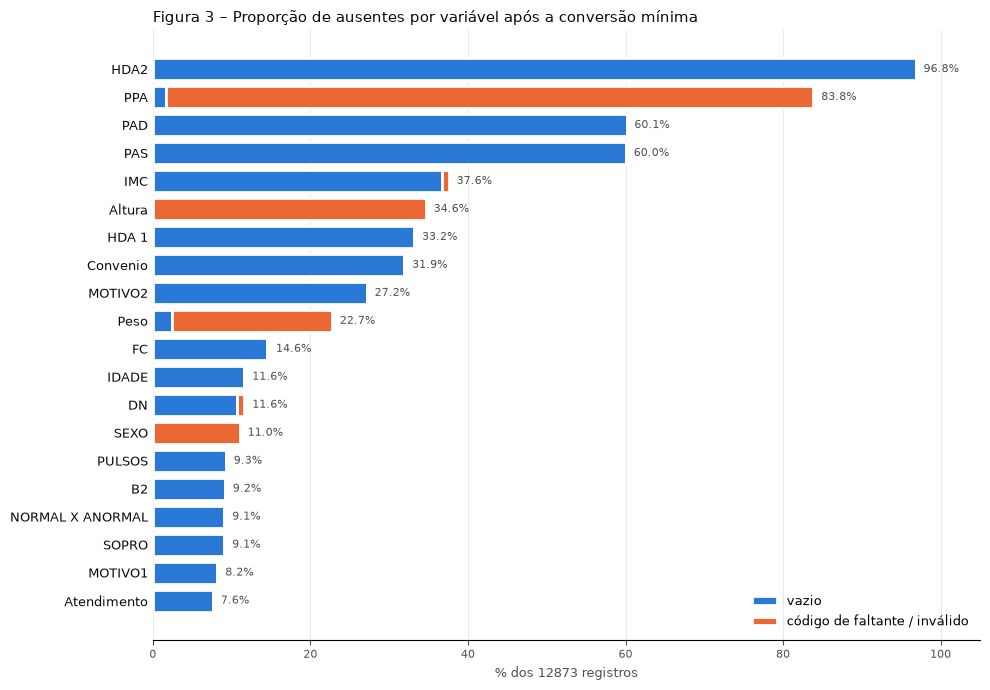

In [14]:
# %%
LARANJA = "#eb6834"

colunas_finais = {
    "Peso": ("Peso", "Peso_limpo"), "Altura": ("Altura", "Altura_limpo"),
    "IMC": ("IMC", "IMC_limpo"), "IDADE": ("IDADE", "IDADE_limpo"),
    "PAS": ("PA SISTOLICA", "PAS_num"), "PAD": ("PA DIASTOLICA", "PAD_num"),
    "FC": ("FC", "FC_num"), "Atendimento": ("Atendimento", "Atendimento_dt"),
    "DN": ("DN", "DN_dt"), "Convenio": ("Convenio", "Convenio"),
    "PULSOS": ("PULSOS", "PULSOS_pad"), "B2": ("B2", "B2"), "SOPRO": ("SOPRO", "SOPRO_pad"),
    "PPA": ("PPA", "PPA_limpo"), "NORMAL X ANORMAL": ("NORMAL X ANORMAL", "ALVO_pad"),
    "SEXO": ("SEXO", "SEXO_pad"), "HDA 1": ("HDA 1", "HDA 1"), "HDA2": ("HDA2", "HDA2"),
    "MOTIVO1": ("MOTIVO1", "MOTIVO1"), "MOTIVO2": ("MOTIVO2", "MOTIVO2"),
}

linhas = []
for nome, (bruta, final) in colunas_finais.items():
    vazio = (df[bruta].str.strip() == "").sum()
    ausente_final = df[final].replace("", pd.NA).isna().sum()
    linhas.append({"Variável": nome,
                   "vazio": vazio / n_total * 100,
                   "código/inválido": (ausente_final - vazio) / n_total * 100})

ausentes = pd.DataFrame(linhas).set_index("Variável")
ausentes["total"] = ausentes["vazio"] + ausentes["código/inválido"]
ausentes = ausentes.sort_values("total")
print(ausentes.round(1))

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(ausentes.index, ausentes["vazio"], color=AZUL, edgecolor="white", linewidth=2, label="vazio")
ax.barh(ausentes.index, ausentes["código/inválido"], left=ausentes["vazio"], color=LARANJA,
        edgecolor="white", linewidth=2, label="código de faltante / inválido")
for i, total in enumerate(ausentes["total"]):
    rotulo = f"{total:.1f}%" if total >= 0.1 else "<0.1%"
    ax.text(total + 1, i, rotulo, va="center", fontsize=8, color=TEXTO2)

ax.set_xlim(0, 105)
ax.set_xlabel("% dos 12873 registros", fontsize=9, color=TEXTO2)
ax.grid(axis="x", color=GRADE, linewidth=0.6)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="x", colors=TEXTO2, labelsize=8)
ax.tick_params(axis="y", colors=TEXTO, labelsize=9, length=0)
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.set_title("Figura 3 – Proporção de ausentes por variável após a conversão mínima",
             loc="left", fontsize=11, color=TEXTO)
fig.tight_layout()
fig.savefig(PASTA / "fig3_ausentes.png", dpi=200, bbox_inches="tight")
plt.show()

In [15]:
# %%
ausente = pd.DataFrame({nome: df[final].replace("", pd.NA).isna()
                        for nome, (bruta, final) in colunas_finais.items()})
estrutural_HDA2 = (df["HDA2"] == "") & (df["HDA 1"] != "")
estrutural_MOTIVO2 = (df["MOTIVO2"] == "") & (df["MOTIVO1"] == "2 - Check-up")
ausente.loc[estrutural_HDA2, "HDA2"] = False
ausente.loc[estrutural_MOTIVO2, "MOTIVO2"] = False
frac_ausente = ausente.mean(axis=1)
atributos_brutos = [bruta for bruta, final in colunas_finais.values()]

passo1 = df.duplicated(subset=atributos_brutos, keep="first")
passo2 = ~passo1 & (frac_ausente > 0.5)
passo3 = ~passo1 & ~passo2 & ausente["NORMAL X ANORMAL"]
manter = ~(passo1 | passo2 | passo3)

print("1) duplicatas exatas (sem ID):", passo1.sum())
print("2) mais de 50% dos atributos ausentes:", passo2.sum())
print("3) sem alvo:", passo3.sum())
print("restam:", manter.sum(), "de", n_total)

for limiar in [0.4, 0.5, 0.6]:
    print(f"   limiar {limiar:.0%}: {(~passo1 & (frac_ausente > limiar)).sum()} objetos")

antes = df["ALVO_pad"].replace("", pd.NA).dropna()
depois = df.loc[manter, "ALVO_pad"]
print(f"% Anormal: antes {(antes == 'Anormal').mean()*100:.1f} | depois {(depois == 'Anormal').mean()*100:.1f}")

df_limpo = df[manter].copy()

1) duplicatas exatas (sem ID): 987
2) mais de 50% dos atributos ausentes: 161
3) sem alvo: 301
restam: 11424 de 12873
   limiar 40%: 610 objetos
   limiar 50%: 161 objetos
   limiar 60%: 79 objetos
% Anormal: antes 42.4 | depois 42.7
